# Day 095 | Reduced-Order Modeling for Geotechnics

## 100 Days of ML for Geotechnical Engineering
**Phase:** Geotechnical AI Projects

**Author:** Ripon Chandra Malo

---

## Project Overview

**Objective:** Build PCA-based reduced-order models (ROMs) combined with ML surrogate models to approximate expensive FEM simulation outputs. In geotechnical engineering, a single FEM run for embankment settlement or excavation can take hours. A surrogate trained on a few hundred runs can predict results in milliseconds.

**Workflow:**
1. Generate synthetic FEM results (150 soil profiles with settlement, displacement, stress outputs)
2. Apply PCA to reduce dimensionality of the output space
3. Train ML surrogates (Random Forest, SVR, Gradient Boosting) on reduced outputs
4. Compare speed vs accuracy trade-offs
5. Reconstruct full output from reduced representation

---

## Part 1: Imports and Setup

In [1]:
# ─────────────────────────────────────────────────────
# IMPORTS
# ─────────────────────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import time
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
print("Libraries loaded.")

Libraries loaded.


---

## Part 2: Generate Synthetic FEM Results

We simulate an embankment settlement FEM study. Each simulation has input parameters (soil properties, geometry) and outputs (settlement profile at multiple points, stress distribution).

In [2]:
# ─────────────────────────────────────────────────────
# GENERATE SYNTHETIC FEM INPUT/OUTPUT DATA (150 runs)
# ─────────────────────────────────────────────────────

n_sims = 150
n_output_points = 20  # Settlement at 20 locations along embankment

# INPUT PARAMETERS (soil + geometry)
E_soil = np.random.uniform(5, 50, n_sims)       # Young's modulus (MPa)
nu = np.random.uniform(0.25, 0.45, n_sims)       # Poisson's ratio
cohesion = np.random.uniform(5, 50, n_sims)       # Cohesion (kPa)
phi = np.random.uniform(15, 40, n_sims)            # Friction angle (deg)
gamma = np.random.uniform(16, 22, n_sims)          # Unit weight (kN/m3)
H_emb = np.random.uniform(3, 12, n_sims)           # Embankment height (m)
B_emb = np.random.uniform(10, 40, n_sims)          # Embankment width (m)
depth_soft = np.random.uniform(5, 20, n_sims)      # Soft layer depth (m)

X_inputs = np.column_stack([E_soil, nu, cohesion, phi, gamma, H_emb, B_emb, depth_soft])
input_names = ['E_MPa', 'nu', 'Cohesion_kPa', 'Phi_deg', 
               'Gamma_kN_m3', 'H_emb_m', 'B_emb_m', 'Depth_soft_m']

df_inputs = pd.DataFrame(X_inputs, columns=input_names)

# OUTPUT: Settlement profile (synthetic, physics-inspired)
x_positions = np.linspace(0, 1, n_output_points)  # Normalized position

Y_outputs = np.zeros((n_sims, n_output_points))
for i in range(n_sims):
    # Maximum settlement ~ load / stiffness * depth
    max_settle = (gamma[i] * H_emb[i] * depth_soft[i]) / (E_soil[i] * 1000) * 1000  # mm
    # Bell-shaped settlement profile
    profile = max_settle * np.exp(-((x_positions - 0.5)**2) / (0.1 + 0.05 * B_emb[i]/20))
    # Add some noise
    profile += np.random.normal(0, max_settle * 0.03, n_output_points)
    Y_outputs[i, :] = profile

output_names = [f'Settle_{j+1}_mm' for j in range(n_output_points)]
df_outputs = pd.DataFrame(Y_outputs, columns=output_names)

print(f"FEM simulations: {n_sims}")
print(f"Input parameters: {len(input_names)}")
print(f"Output points per simulation: {n_output_points}")
print(f"\nInput ranges:")
df_inputs.describe().round(2)

FEM simulations: 150
Input parameters: 8
Output points per simulation: 20

Input ranges:


,E_MPa,nu,Cohesion_kPa,Phi_deg,Gamma_kN_m3,H_emb_m,B_emb_m,Depth_soft_m
count,150.00,150.00,150.00,150.00,150.00,150.00,150.00,150.00
mean,26.28,0.35,27.33,28.14,18.77,7.33,24.80,13.18
std,13.34,0.06,13.56,7.60,1.65,2.63,8.80,4.48
min,5.25,0.25,5.49,15.28,16.12,3.04,10.33,5.10
25%,14.67,0.30,16.18,21.55,17.30,4.86,17.42,8.99
50%,25.17,0.36,27.69,28.30,18.61,7.20,25.23,13.89
75%,38.73,0.40,38.89,35.31,20.09,9.50,31.97,17.21
max,49.41,0.45,49.57,39.99,21.94,11.97,39.63,19.97


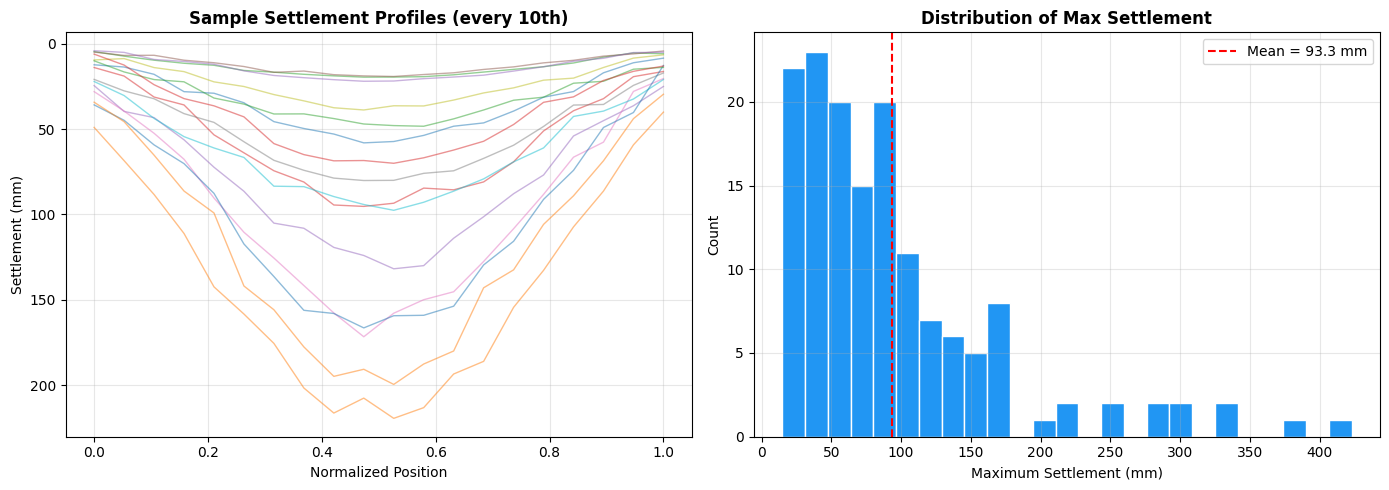

In [3]:
# ─────────────────────────────────────────────────────
# VISUALIZE SETTLEMENT PROFILES
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot sample profiles
for i in range(0, n_sims, 10):
    axes[0].plot(x_positions, Y_outputs[i, :], alpha=0.5, linewidth=1)
axes[0].set_xlabel('Normalized Position')
axes[0].set_ylabel('Settlement (mm)')
axes[0].set_title('Sample Settlement Profiles (every 10th)', fontweight='bold')
axes[0].invert_yaxis()
axes[0].grid(True, alpha=0.3)

# Max settlement distribution
max_settlements = Y_outputs.max(axis=1)
axes[1].hist(max_settlements, bins=25, color='#2196F3', edgecolor='white')
axes[1].set_xlabel('Maximum Settlement (mm)')
axes[1].set_ylabel('Count')
axes[1].set_title('Distribution of Max Settlement', fontweight='bold')
axes[1].axvline(max_settlements.mean(), color='red', linestyle='--', 
                label=f'Mean = {max_settlements.mean():.1f} mm')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

## Part 3: PCA on Output Space

The 20-dimensional output (settlement at 20 points) has strong internal correlations. PCA finds the principal modes of variation, allowing us to represent each profile with just a few numbers.

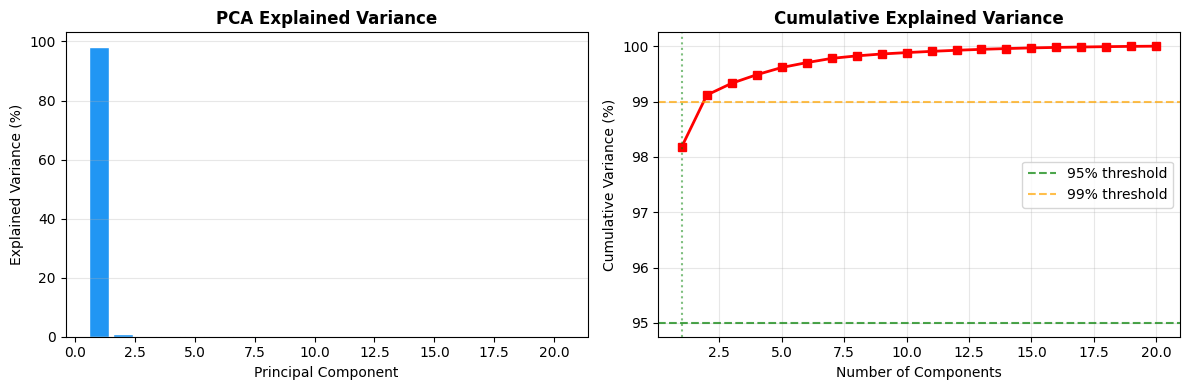

Components for 95% variance: 1
Components for 99% variance: 2
Dimensionality reduction: 20 -> 1 (95% variance)


In [4]:
# ─────────────────────────────────────────────────────
# PCA ON OUTPUT SPACE
# ─────────────────────────────────────────────────────

# Standardize outputs
scaler_Y = StandardScaler()
Y_scaled = scaler_Y.fit_transform(Y_outputs)

# Fit PCA
pca_full = PCA()
pca_full.fit(Y_scaled)

# Explained variance
cumvar = np.cumsum(pca_full.explained_variance_ratio_) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.bar(range(1, n_output_points+1), pca_full.explained_variance_ratio_ * 100,
        color='#2196F3', edgecolor='white')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance (%)')
ax1.set_title('PCA Explained Variance', fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')

ax2.plot(range(1, n_output_points+1), cumvar, 'rs-', linewidth=2)
ax2.axhline(y=95, color='green', linestyle='--', alpha=0.7, label='95% threshold')
ax2.axhline(y=99, color='orange', linestyle='--', alpha=0.7, label='99% threshold')
n_95 = np.argmax(cumvar >= 95) + 1
n_99 = np.argmax(cumvar >= 99) + 1
ax2.axvline(x=n_95, color='green', linestyle=':', alpha=0.5)
ax2.set_xlabel('Number of Components')
ax2.set_ylabel('Cumulative Variance (%)')
ax2.set_title('Cumulative Explained Variance', fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Components for 95% variance: {n_95}")
print(f"Components for 99% variance: {n_99}")
print(f"Dimensionality reduction: {n_output_points} -> {n_95} (95% variance)")

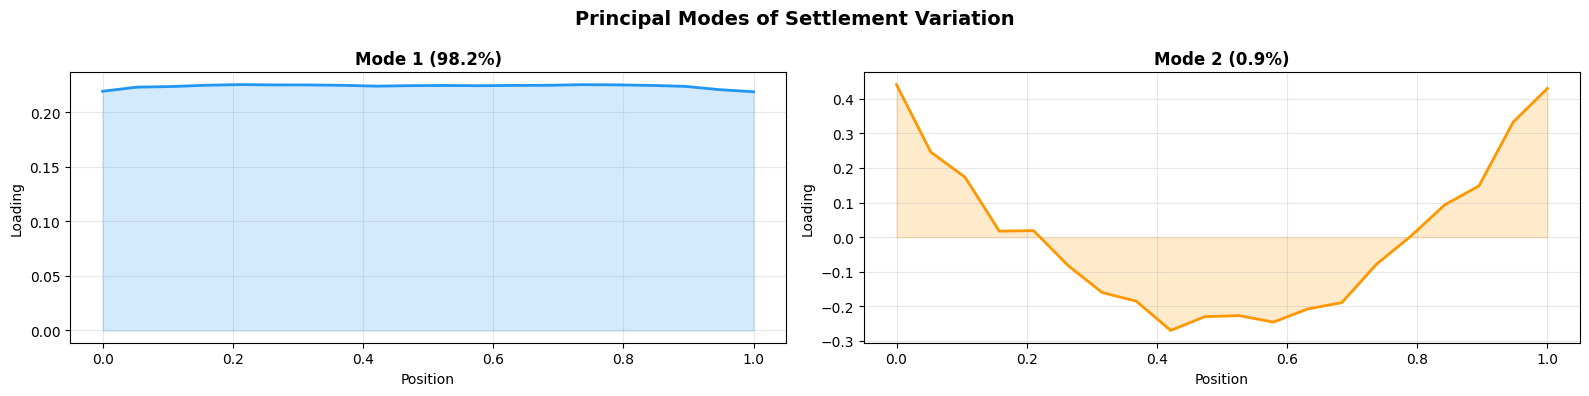

Mode 1: Overall magnitude (uniform scaling)
Mode 2: Asymmetry (tilt of the settlement bowl)
Mode 3: Width variation (narrow vs wide bowl)


In [5]:
# ─────────────────────────────────────────────────────
# VISUALIZE PCA MODES (principal shapes)
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, min(4, n_95+1), figsize=(16, 4))
mode_colors = ['#2196F3', '#FF9800', '#4CAF50', '#F44336']

for i in range(min(4, n_95+1)):
    axes[i].plot(x_positions, pca_full.components_[i], 
                 color=mode_colors[i], linewidth=2)
    axes[i].fill_between(x_positions, pca_full.components_[i], 
                         alpha=0.2, color=mode_colors[i])
    axes[i].set_title(f'Mode {i+1} ({pca_full.explained_variance_ratio_[i]*100:.1f}%)',
                      fontweight='bold')
    axes[i].set_xlabel('Position')
    axes[i].set_ylabel('Loading')
    axes[i].grid(True, alpha=0.3)

fig.suptitle('Principal Modes of Settlement Variation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Mode 1: Overall magnitude (uniform scaling)")
print("Mode 2: Asymmetry (tilt of the settlement bowl)")
print("Mode 3: Width variation (narrow vs wide bowl)")

In [6]:
# ─────────────────────────────────────────────────────
# REDUCE OUTPUTS
# ─────────────────────────────────────────────────────

n_components = n_95  # Use 95% variance threshold
pca = PCA(n_components=n_components)
Y_reduced = pca.fit_transform(Y_scaled)

print(f"Reduced output shape: {Y_reduced.shape}")
print(f"Compression ratio: {n_output_points}/{n_components} = {n_output_points/n_components:.1f}x")

# Verify reconstruction quality
Y_reconstructed = scaler_Y.inverse_transform(pca.inverse_transform(Y_reduced))
recon_error = np.mean((Y_outputs - Y_reconstructed)**2)**0.5
print(f"Reconstruction RMSE: {recon_error:.4f} mm")

Reduced output shape: (150, 1)
Compression ratio: 20/1 = 20.0x
Reconstruction RMSE: 5.5921 mm


---

## Part 4: Train Surrogate Models

We train ML models to map inputs (soil properties + geometry) directly to PCA coefficients. This replaces the FEM simulation entirely.

In [7]:
# ─────────────────────────────────────────────────────
# PREPARE TRAIN/TEST SPLIT
# ─────────────────────────────────────────────────────

# Scale inputs
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X_inputs)

X_train, X_test, Y_train, Y_test = train_test_split(
    X_scaled, Y_reduced, test_size=0.2, random_state=42
)

# Also keep unscaled outputs for reconstruction
_, _, Y_train_full, Y_test_full = train_test_split(
    X_inputs, Y_outputs, test_size=0.2, random_state=42
)

print(f"Train: {X_train.shape[0]} samples")
print(f"Test:  {X_test.shape[0]} samples")
print(f"Input features: {X_train.shape[1]}")
print(f"Output PCA components: {Y_train.shape[1]}")

Train: 120 samples
Test:  30 samples
Input features: 8
Output PCA components: 1


In [8]:
# ─────────────────────────────────────────────────────
# TRAIN SURROGATE MODELS
# ─────────────────────────────────────────────────────

models = {
    'Random Forest': MultiOutputRegressor(
        RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
    ),
    'Gradient Boosting': MultiOutputRegressor(
        GradientBoostingRegressor(n_estimators=100, max_depth=5, random_state=42)
    ),
    'SVR (RBF)': MultiOutputRegressor(
        SVR(kernel='rbf', C=10, epsilon=0.1)
    ),
}

results = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    
    # Train
    t_start = time.time()
    model.fit(X_train, Y_train)
    train_time = time.time() - t_start
    
    # Predict
    t_start = time.time()
    Y_pred_reduced = model.predict(X_test)
    predict_time = time.time() - t_start
    
    # Reconstruct full output
    Y_pred_full = scaler_Y.inverse_transform(pca.inverse_transform(Y_pred_reduced))
    
    # Metrics on full output
    rmse = np.sqrt(mean_squared_error(Y_test_full, Y_pred_full))
    mae = mean_absolute_error(Y_test_full, Y_pred_full)
    r2 = r2_score(Y_test_full, Y_pred_full)
    
    results[name] = {
        'model': model,
        'RMSE_mm': rmse,
        'MAE_mm': mae,
        'R2': r2,
        'Train_s': train_time,
        'Predict_s': predict_time,
        'Predict_per_sample_ms': predict_time / len(X_test) * 1000,
        'Y_pred_full': Y_pred_full,
    }
    
    print(f"  RMSE: {rmse:.3f} mm | MAE: {mae:.3f} mm | R2: {r2:.4f}")
    print(f"  Train: {train_time:.3f}s | Predict: {predict_time*1000:.1f}ms total")


Training Random Forest...


  RMSE: 28.768 mm | MAE: 19.222 mm | R2: 0.7740
  Train: 0.192s | Predict: 10.1ms total

Training Gradient Boosting...
  RMSE: 26.792 mm | MAE: 15.900 mm | R2: 0.8015
  Train: 0.092s | Predict: 0.9ms total

Training SVR (RBF)...
  RMSE: 32.659 mm | MAE: 17.091 mm | R2: 0.7033
  Train: 0.006s | Predict: 0.9ms total


---

## Part 5: Compare Models

In [9]:
# ─────────────────────────────────────────────────────
# MODEL COMPARISON TABLE
# ─────────────────────────────────────────────────────

comparison = pd.DataFrame({
    name: {
        'RMSE (mm)': r['RMSE_mm'],
        'MAE (mm)': r['MAE_mm'],
        'R2': r['R2'],
        'Train Time (s)': r['Train_s'],
        'Predict/sample (ms)': r['Predict_per_sample_ms'],
    }
    for name, r in results.items()
}).T

print("Surrogate Model Comparison:")
comparison.round(4)

Surrogate Model Comparison:


,RMSE (mm),MAE (mm),R2,Train Time (s),Predict/sample (ms)
Random Forest,28.7677,19.2224,0.7740,0.1924,0.3372
Gradient Boosting,26.7923,15.8998,0.8015,0.0919,0.0304
SVR (RBF),32.6587,17.0907,0.7033,0.0060,0.0297


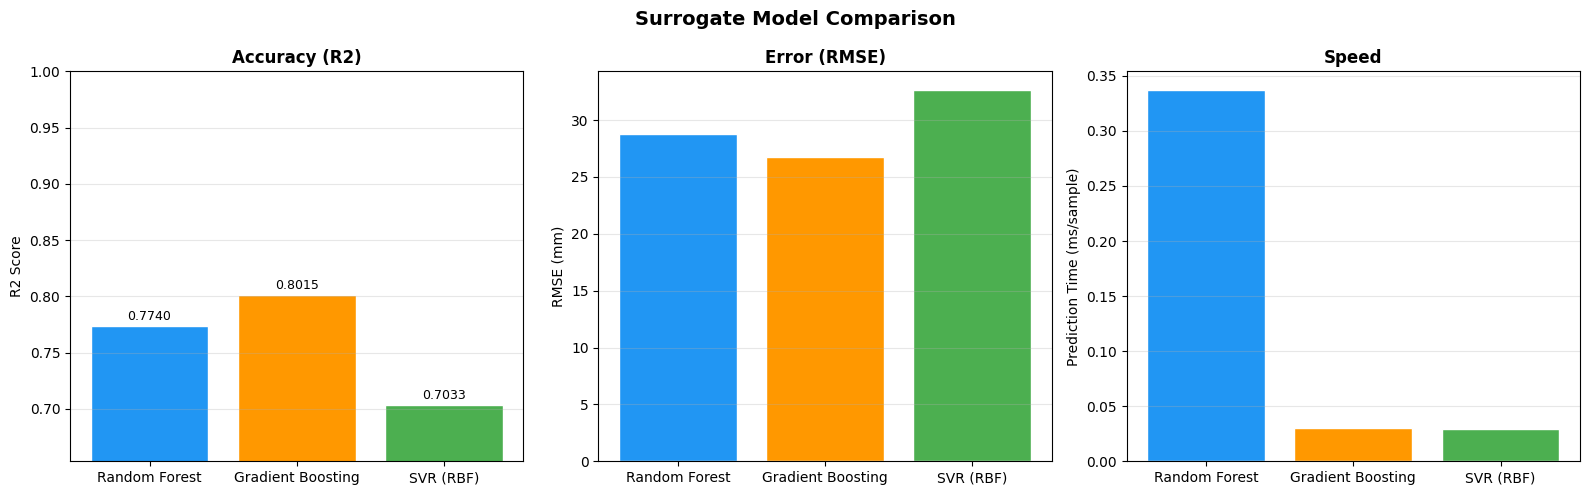

In [10]:
# ─────────────────────────────────────────────────────
# VISUAL COMPARISON
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

model_names = list(results.keys())
colors = ['#2196F3', '#FF9800', '#4CAF50']

# R2 scores
r2_vals = [results[m]['R2'] for m in model_names]
axes[0].bar(model_names, r2_vals, color=colors, edgecolor='white')
axes[0].set_ylabel('R2 Score')
axes[0].set_title('Accuracy (R2)', fontweight='bold')
axes[0].set_ylim(min(r2_vals) - 0.05, 1.0)
axes[0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(r2_vals):
    axes[0].text(i, v + 0.005, f'{v:.4f}', ha='center', fontsize=9)

# RMSE
rmse_vals = [results[m]['RMSE_mm'] for m in model_names]
axes[1].bar(model_names, rmse_vals, color=colors, edgecolor='white')
axes[1].set_ylabel('RMSE (mm)')
axes[1].set_title('Error (RMSE)', fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

# Speed
speed_vals = [results[m]['Predict_per_sample_ms'] for m in model_names]
axes[2].bar(model_names, speed_vals, color=colors, edgecolor='white')
axes[2].set_ylabel('Prediction Time (ms/sample)')
axes[2].set_title('Speed', fontweight='bold')
axes[2].grid(True, alpha=0.3, axis='y')

fig.suptitle('Surrogate Model Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---

## Part 6: Profile Reconstruction Quality

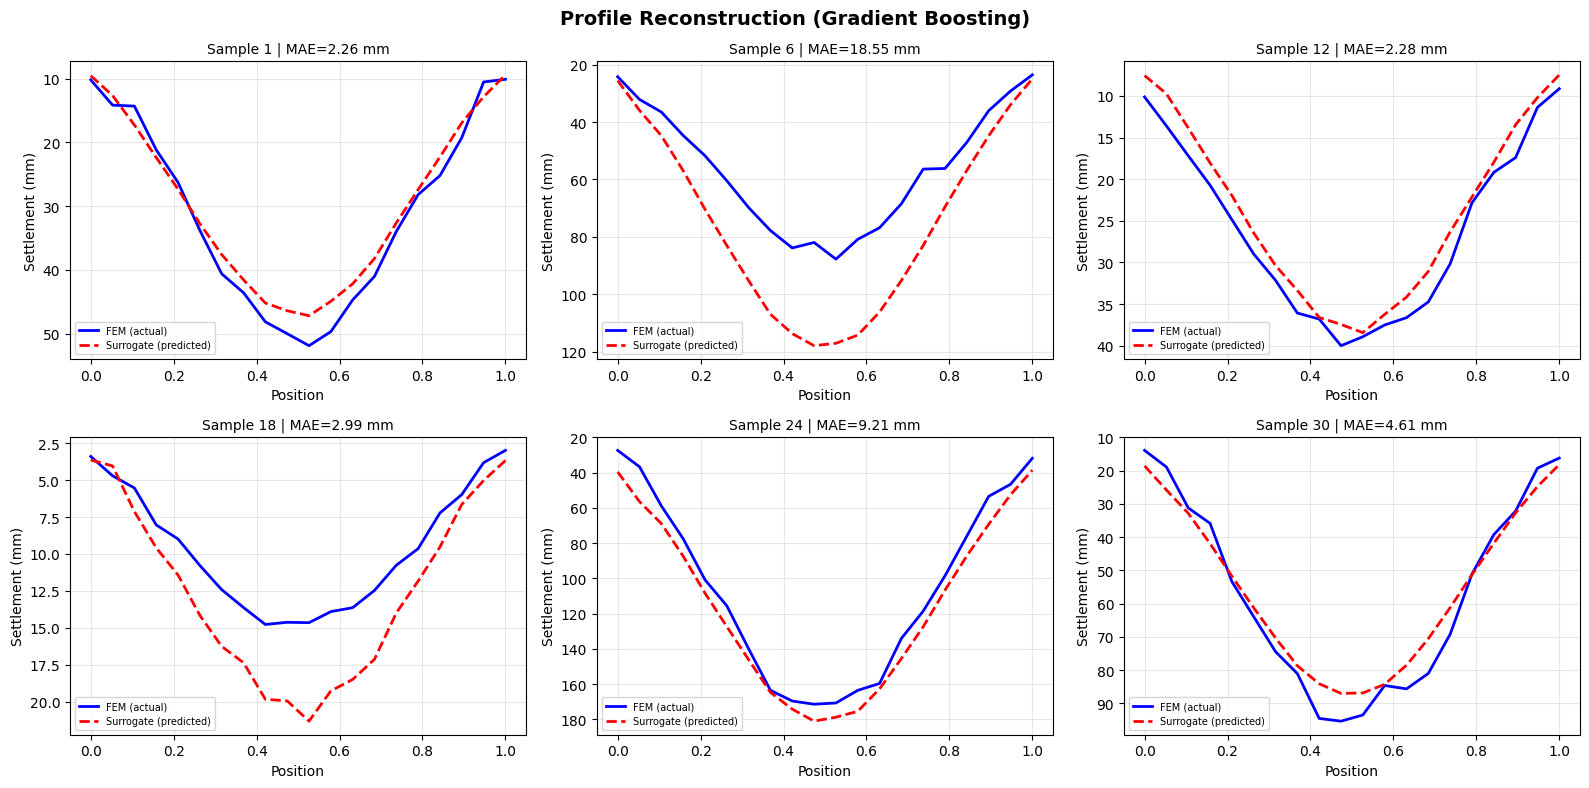

In [11]:
# ─────────────────────────────────────────────────────
# COMPARE PREDICTED vs ACTUAL PROFILES
# ─────────────────────────────────────────────────────

best_model_name = max(results, key=lambda m: results[m]['R2'])
best_pred = results[best_model_name]['Y_pred_full']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

sample_indices = np.linspace(0, len(Y_test_full)-1, 6, dtype=int)

for idx, ax in zip(sample_indices, axes):
    ax.plot(x_positions, Y_test_full[idx], 'b-', linewidth=2, label='FEM (actual)')
    ax.plot(x_positions, best_pred[idx], 'r--', linewidth=2, label='Surrogate (predicted)')
    error = np.abs(Y_test_full[idx] - best_pred[idx]).mean()
    ax.set_title(f'Sample {idx+1} | MAE={error:.2f} mm', fontsize=10)
    ax.set_xlabel('Position')
    ax.set_ylabel('Settlement (mm)')
    ax.invert_yaxis()
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

fig.suptitle(f'Profile Reconstruction ({best_model_name})', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

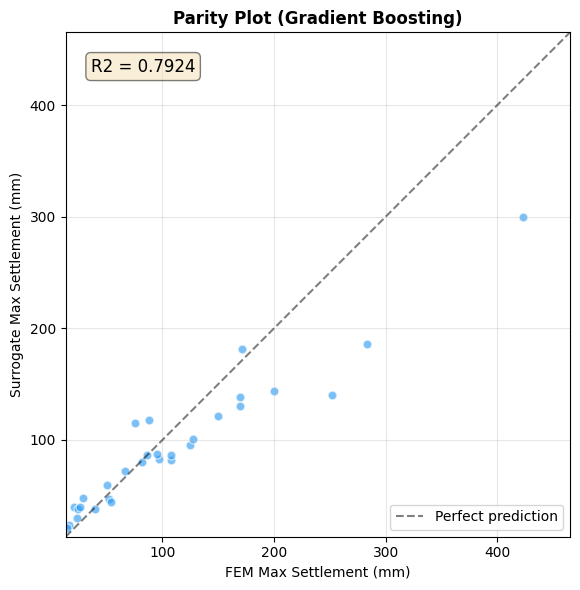

In [12]:
# ─────────────────────────────────────────────────────
# PARITY PLOT: MAX SETTLEMENT
# ─────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(6, 6))

actual_max = Y_test_full.max(axis=1)
pred_max = best_pred.max(axis=1)

ax.scatter(actual_max, pred_max, c='#2196F3', s=40, alpha=0.6, edgecolors='white')
lims = [min(actual_max.min(), pred_max.min()) * 0.9,
        max(actual_max.max(), pred_max.max()) * 1.1]
ax.plot(lims, lims, 'k--', alpha=0.5, label='Perfect prediction')
ax.set_xlabel('FEM Max Settlement (mm)')
ax.set_ylabel('Surrogate Max Settlement (mm)')
ax.set_title(f'Parity Plot ({best_model_name})', fontweight='bold')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect('equal')
ax.legend()
ax.grid(True, alpha=0.3)

r2_max = r2_score(actual_max, pred_max)
ax.text(0.05, 0.95, f'R2 = {r2_max:.4f}', transform=ax.transAxes,
        fontsize=12, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

---

## Part 7: Speed vs Accuracy Trade-off

In [13]:
# ─────────────────────────────────────────────────────
# SPEED VS ACCURACY ANALYSIS
# ─────────────────────────────────────────────────────

# Simulate FEM time (assume 30 min per run)
fem_time_per_run_s = 30 * 60  # 30 minutes in seconds
n_new_predictions = 1000

print("Speed Comparison: FEM vs Surrogate")
print("=" * 55)
print(f"\nScenario: Predict {n_new_predictions} new configurations")
print(f"\nFEM (assumed):")
print(f"  Time per run:    30 min")
print(f"  Total time:      {n_new_predictions * fem_time_per_run_s / 3600:.0f} hours")
print(f"  Accuracy:        Exact (reference)")

for name, r in results.items():
    total_predict = n_new_predictions * r['Predict_per_sample_ms'] / 1000
    speedup = (n_new_predictions * fem_time_per_run_s) / total_predict
    print(f"\n{name}:")
    print(f"  Time per sample: {r['Predict_per_sample_ms']:.2f} ms")
    print(f"  Total time:      {total_predict:.1f} s")
    print(f"  Speedup:         {speedup:.0f}x faster")
    print(f"  R2:              {r['R2']:.4f}")
    print(f"  RMSE:            {r['RMSE_mm']:.3f} mm")

Speed Comparison: FEM vs Surrogate

Scenario: Predict 1000 new configurations

FEM (assumed):
  Time per run:    30 min
  Total time:      500 hours
  Accuracy:        Exact (reference)

Random Forest:
  Time per sample: 0.34 ms
  Total time:      0.3 s
  Speedup:         5337648x faster
  R2:              0.7740
  RMSE:            28.768 mm

Gradient Boosting:
  Time per sample: 0.03 ms
  Total time:      0.0 s
  Speedup:         59198227x faster
  R2:              0.8015
  RMSE:            26.792 mm

SVR (RBF):
  Time per sample: 0.03 ms
  Total time:      0.0 s
  Speedup:         60559470x faster
  R2:              0.7033
  RMSE:            32.659 mm


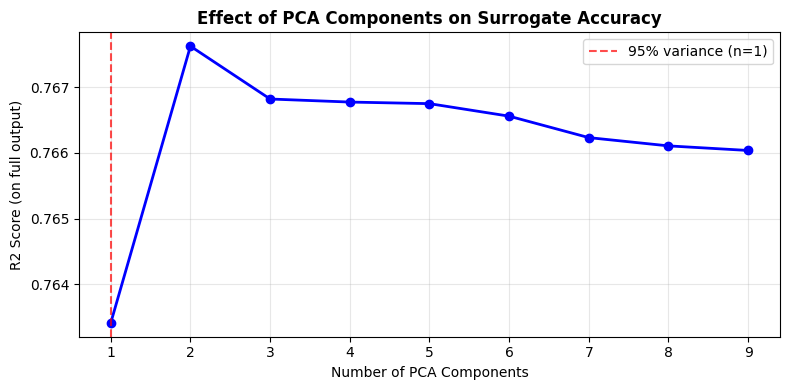

In [14]:
# ─────────────────────────────────────────────────────
# EFFECT OF NUMBER OF PCA COMPONENTS
# ─────────────────────────────────────────────────────

component_range = range(1, min(10, n_output_points))
r2_by_components = []

for nc in component_range:
    pca_temp = PCA(n_components=nc)
    Y_red_temp = pca_temp.fit_transform(Y_scaled)
    
    Xtr, Xte, Ytr, Yte = train_test_split(X_scaled, Y_red_temp, 
                                           test_size=0.2, random_state=42)
    _, _, _, Yte_full = train_test_split(X_inputs, Y_outputs, 
                                         test_size=0.2, random_state=42)
    
    rf = MultiOutputRegressor(
        RandomForestRegressor(n_estimators=50, max_depth=8, random_state=42)
    )
    rf.fit(Xtr, Ytr)
    Ypred_red = rf.predict(Xte)
    Ypred_full = scaler_Y.inverse_transform(pca_temp.inverse_transform(Ypred_red))
    
    r2_by_components.append(r2_score(Yte_full, Ypred_full))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(component_range), r2_by_components, 'bo-', linewidth=2)
ax.set_xlabel('Number of PCA Components')
ax.set_ylabel('R2 Score (on full output)')
ax.set_title('Effect of PCA Components on Surrogate Accuracy', fontweight='bold')
ax.grid(True, alpha=0.3)
ax.axvline(x=n_95, color='red', linestyle='--', alpha=0.7, 
           label=f'95% variance (n={n_95})')
ax.legend()
plt.tight_layout()
plt.show()

---

## Part 8: Feature Importance for Surrogate

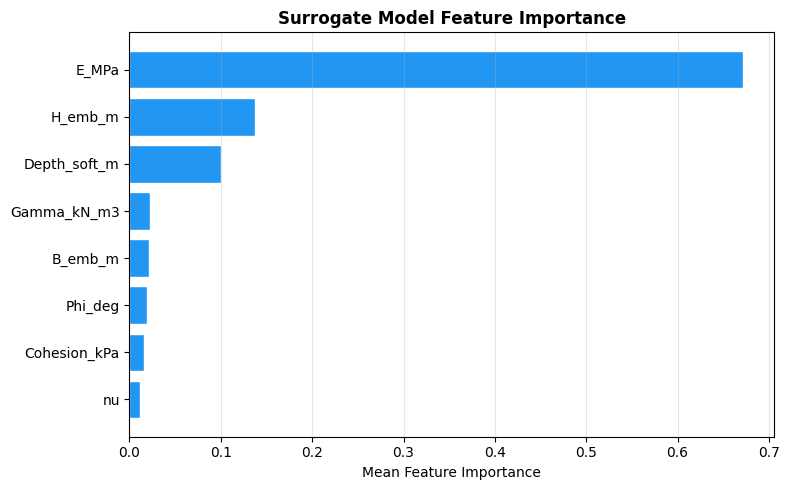

Most important inputs for settlement prediction:
  E_MPa               : 0.6717
  H_emb_m             : 0.1373
  Depth_soft_m        : 0.1006
  Gamma_kN_m3         : 0.0225
  B_emb_m             : 0.0212
  Phi_deg             : 0.0195
  Cohesion_kPa        : 0.0155
  nu                  : 0.0116


In [15]:
# ─────────────────────────────────────────────────────
# FEATURE IMPORTANCE
# ─────────────────────────────────────────────────────

# Use Random Forest feature importance (average across output components)
rf_model = results['Random Forest']['model']
importances = np.mean([
    est.feature_importances_ for est in rf_model.estimators_
], axis=0)

fi_df = pd.DataFrame({
    'Feature': input_names,
    'Importance': importances
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(fi_df['Feature'], fi_df['Importance'], color='#2196F3', edgecolor='white')
ax.set_xlabel('Mean Feature Importance')
ax.set_title('Surrogate Model Feature Importance', fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print("Most important inputs for settlement prediction:")
for _, row in fi_df.sort_values('Importance', ascending=False).iterrows():
    print(f"  {row['Feature']:20s}: {row['Importance']:.4f}")

---

## Key Takeaways

1. **PCA compresses correlated outputs** dramatically. A 20-point settlement profile can often be represented by 2-4 principal components capturing 95%+ variance.

2. **ML surrogates replace expensive FEM** simulations for parametric studies. Once trained on ~100-200 FEM runs, they predict new cases in milliseconds -- enabling Monte Carlo analysis, optimization, and real-time decision support.

3. **The PCA + ML pipeline** is general: compress output with PCA, train ML on the reduced space, reconstruct full output. Works for any high-dimensional FEM output.

4. **Random Forest and Gradient Boosting** are strong baseline surrogates. For problems with more complex input-output mappings, neural networks or Gaussian Processes may be needed.

5. **Feature importance reveals physics**: embankment height and soil stiffness dominate settlement -- exactly what geotechnical theory predicts.

---

## Next Steps

- Day 096: Build a Streamlit dashboard for geotechnical ML
- Add Gaussian Process surrogates with uncertainty quantification
- Apply to real FEM outputs (PLAXIS, FLAC3D export files)

---

*Day 095 of 100 -- Surrogates make the impossible parametric study possible!*